## Correlation Main Computation (long)

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import os
import pandas as pd
from scipy.spatial import distance_matrix
import gc
import re

results_for_aspect_ratio_10 = {}

thickness = 0.1
trials = range(1, 6)

bins = np.linspace(0, 1, 50)  # Use r/R bins from 0 to 1


def compute_radius(df):
    x, y = df[["x", "y"]].T.values
    center_x, center_y = np.mean(x), np.mean(y)
    distances_to_center = np.sqrt((x - center_x) ** 2 + (y - center_y) ** 2)
    R = np.max(distances_to_center)
    return R


def compute_correlation(df, thickness, R, path):
    x, y, color2 = df[["x", "y", "color2"]].T.values

    # Get a's
    match = re.search(r'(division_lengths|MAR):([\d.]+),([\d.]+)', path)
    if match:
        asp1 = round(float(match.group(2)) / 0.1, 0) if match.group(1) == 'division_lengths' else float(match.group(2))
        asp2 = round(float(match.group(3)) / 0.1, 0) if match.group(1) == 'division_lengths' else float(match.group(3))
    else:
       
        print(f"Regex did not match for path: {path}")
        return None, None, None

    # only calc asp 10 ones
    if asp1 != 10 and asp2 != 10:
        return None, None, None

    
    if asp1 == 10.0:
        aspect_ratio_key = (asp1, asp2)
    elif asp2 == 10.0:
        aspect_ratio_key = (asp2, asp1)
    else:
        
        return None, None, None

    
    print(f"Processing aspect ratio key: {aspect_ratio_key}")

   
    positions = np.column_stack((x, y))

  
    distance_memmap = np.memmap('distance_matrix.dat', dtype='float32', mode='w+', shape=(len(x), len(x)))

    # Using chunks to avoid memory errors on rockfish
    chunk_size = 1000  
    for i in range(0, len(x), chunk_size):
        for j in range(i, len(x), chunk_size):
            end_i = min(i + chunk_size, len(x))
            end_j = min(j + chunk_size, len(x))
            chunk_distances = distance_matrix(positions[i:end_i], positions[j:end_j])
            distance_memmap[i:end_i, j:end_j] = chunk_distances
            if i != j:
                distance_memmap[j:end_j, i:end_i] = chunk_distances  

    # normalization
    distance_memmap /= R

    bin_indices = np.digitize(distance_memmap, bins, right=True) - 1  

    
    same_type = color2[:, None] == color2  
    correlation_matrix = np.where(same_type, 1, -1) 

   
    num_bins = len(bins) - 1
    correlation_per_distance = np.zeros(num_bins)
    count_per_distance = np.zeros(num_bins)

    for i in range(len(x)):
        for j in range(i + 1, len(x)): 
            bin_idx = bin_indices[i, j]
            if 0 <= bin_idx < num_bins:
                correlation_per_distance[bin_idx] += correlation_matrix[i, j]
                count_per_distance[bin_idx] += 1

    
    valid_bins = count_per_distance > 0
    avg_correlation = np.zeros(num_bins)
    avg_correlation[valid_bins] = correlation_per_distance[valid_bins] / count_per_distance[valid_bins]

    
    del distance_memmap
    gc.collect()

   

    return aspect_ratio_key, avg_correlation, bins[:-1]

def main():
    all_results = []
    aspect_folders = ['asp10', 'asp2', 'asp3', 'asp4', 'asp5', 'asp6', 'asp7', 'asp8', 'asp9', 'asp11', 'asp12', 'asp13', 'asp14', 'asp15']
    
    for trial in trials:
        for aspect_folder in aspect_folders:
            trial_path = f"/home/mratman1/activeMatterCommunities/workspace/simulations_eqdivtime/{aspect_folder}/run{trial}"
            
            if not os.path.exists(trial_path):
                print(f"Path does not exist: {trial_path}")
                continue

            subfolders = [f.path for f in os.scandir(trial_path) if f.is_dir()]
            
           
            print(f"Processing Trial {trial}, Aspect Folder '{aspect_folder}': {len(subfolders)} subfolders found.")

            for subfolder in subfolders:
                filenames = [f for f in os.listdir(subfolder) if f.endswith('.csv')]
                if not filenames:
                    print(f"No CSV files found in {subfolder}. Skipping.")
                    continue

                numeric_filenames = [f for f in filenames if f.split('.')[0].isdigit()]
                if not numeric_filenames:
                    print(f"No numeric CSV filenames in {subfolder}. Skipping.")
                    continue

                final_time = max(int(f.split('.')[0]) for f in numeric_filenames)

               
                csv_path = os.path.join(subfolder, f"{final_time}.csv")
                if not os.path.exists(csv_path):
                    print(f"CSV file does not exist: {csv_path}. Skipping.")
                    continue

                try:
                    chunk_iter = pd.read_csv(csv_path, chunksize=10000)
                except Exception as e:
                    print(f"Error reading CSV file {csv_path}: {e}. Skipping.")
                    continue

                for chunk in chunk_iter:
                    R = compute_radius(chunk)
                    aspect_ratio_key, avg_correlation, bins_values = compute_correlation(chunk, thickness, R, subfolder)

                    if aspect_ratio_key is None:
                        continue

                    if aspect_ratio_key not in results_for_aspect_ratio_10:
                        results_for_aspect_ratio_10[aspect_ratio_key] = {
                            "avg_correlations": [], "bins": bins_values
                        }

                    results_for_aspect_ratio_10[aspect_ratio_key]["avg_correlations"].append(avg_correlation)

                    
                    del chunk
                    gc.collect()

    
    averaged_results = {}

    for key, data in results_for_aspect_ratio_10.items():
        if not data["avg_correlations"]:
            continue  

        avg_correlations_all_trials = np.mean(data["avg_correlations"], axis=0)
        sem_correlations_all_trials = np.std(data["avg_correlations"], axis=0) / np.sqrt(len(data["avg_correlations"]))

        averaged_results[key] = {
            "avg_correlation": avg_correlations_all_trials,
            "sem_correlation": sem_correlations_all_trials,
            "bins": data["bins"]
        }

  
    filtered_aspects = {key: val for key, val in averaged_results.items() if 2 <= key[1] <= 15}

  
    for (asp1, asp2), data in filtered_aspects.items():
        df = pd.DataFrame({
            'bins': data['bins'],
            'avg_correlation': data['avg_correlation'],
            'sem_correlation': data['sem_correlation'],
            'asp1': asp1,
            'asp2': asp2
        })
        all_results.append(df)

    if all_results:
        
        results_df = pd.concat(all_results, ignore_index=True)

       
        results_df.to_csv("correlation_asp10_paper.csv", index=False)

        print("Results saved to correlation_asp10_paper.csv")
    else:
        print("No results to save.")

if __name__ == "__main__":
    main()


ValueError: not enough values to unpack (expected 3, got 2)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


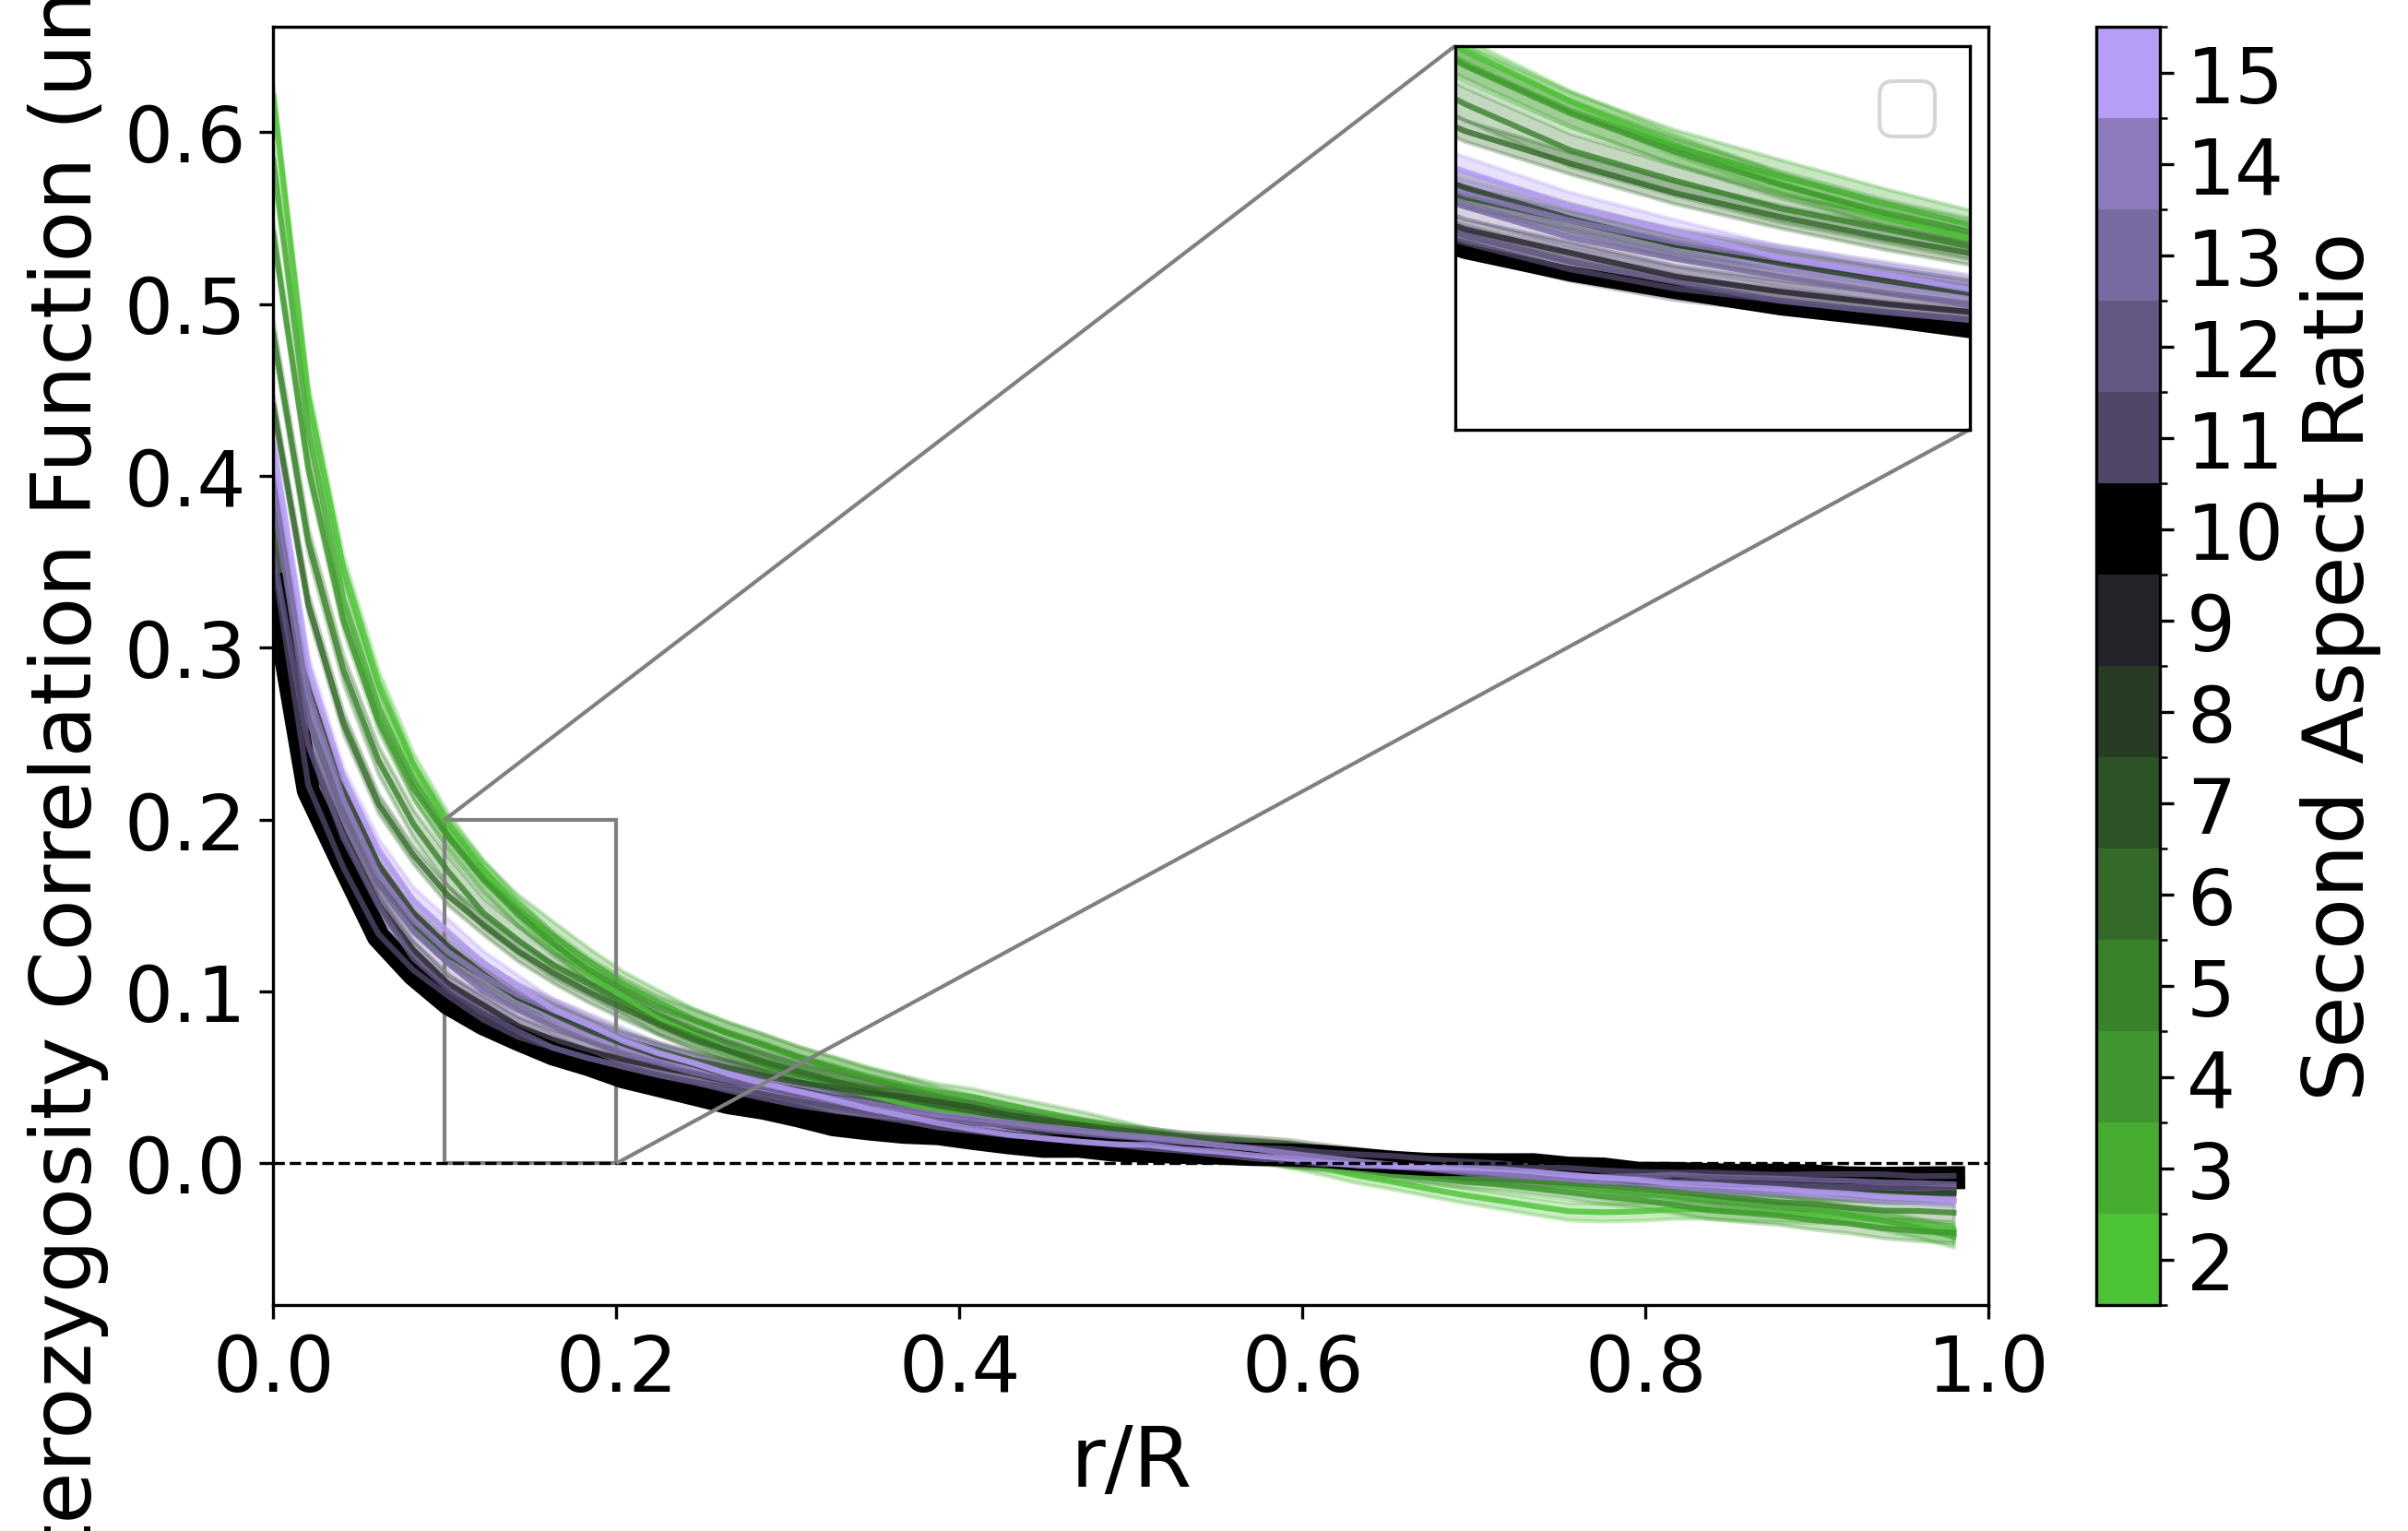

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.cm import ScalarMappable
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
import seaborn as sns

results_df = pd.read_csv("/home/mratman1/activeMatterCommunities/correlation_asp10_paper.csv")

filtered_aspects = {}
for _, row in results_df.iterrows():
    asp1, asp2 = row['asp1'], row['asp2']
    if (asp1, asp2) not in filtered_aspects:
        filtered_aspects[(asp1, asp2)] = {
            'bins': [],
            'avg_correlation': [],
            'sem_correlation': []
        }
    filtered_aspects[(asp1, asp2)]['bins'].append(row['bins'])
    filtered_aspects[(asp1, asp2)]['avg_correlation'].append(row['avg_correlation'])
    filtered_aspects[(asp1, asp2)]['sem_correlation'].append(row['sem_correlation'])

if filtered_aspects:
    sorted_aspects = dict(sorted(filtered_aspects.items(), key=lambda x: x[0][1]))

    fig, ax = plt.subplots(figsize=(10, 6), dpi=300)

    colors = sns.diverging_palette(125, 275, s=90, l=70, n=15, center="dark").as_hex()
    colors[8] = "#000000"

    color_map = ListedColormap(colors)
    bounds = np.arange(2, 17, 1)
    norm = BoundaryNorm(bounds, color_map.N)

    sm = ScalarMappable(cmap=color_map, norm=norm)
    sm.set_array([])

    for (asp1, asp2), data in sorted_aspects.items():
        bins = np.array(data["bins"])
        avg_correlation = np.array(data["avg_correlation"])
        sem_correlation = np.array(data["sem_correlation"])
        color = color_map(norm(asp2))

        if (asp1, asp2) == (10, 10):
            ax.plot(bins, avg_correlation, color='black', linewidth=6, label='Asp2=10 (Thicker)')
        else:
            ax.plot(bins, avg_correlation, color=color, alpha=0.8, label=f"Asp2={asp2}")
            ax.fill_between(bins, avg_correlation - sem_correlation, avg_correlation + sem_correlation, color=color, alpha=0.3)

    ax.set_xlabel("r/R", fontsize=22)
    ax.set_xlim(0, 1)
    ax.axhline(0.0, color='black', linestyle='--', linewidth=0.8)
    ax.set_ylabel("Heterozygosity Correlation Function (units of R)", fontsize=22)
    ax.tick_params(axis='both', which='major', labelsize=20)
    ax.set_yticks([0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6])

    cbar = fig.colorbar(sm, ax=ax, orientation='vertical', boundaries=bounds, ticks=bounds + 0.5)
    cbar.set_label('Second Aspect Ratio', fontsize=22)
    cbar.ax.set_yticklabels([str(int(i)) for i in bounds])
    cbar.ax.tick_params(labelsize=20)

    ax_inset = inset_axes(ax, width="30%", height="30%", loc='upper right')
    for (asp1, asp2), data in sorted_aspects.items():
        bins = np.array(data["bins"])
        avg_correlation = np.array(data["avg_correlation"])
        sem_correlation = np.array(data["sem_correlation"])
        color = color_map(norm(asp2))

        if (asp1, asp2) == (10, 10):
            ax_inset.plot(bins, avg_correlation, color='black', linewidth=4)
        else:
            ax_inset.plot(bins, avg_correlation, color=color, alpha=0.8)
            ax_inset.fill_between(bins, avg_correlation - sem_correlation, avg_correlation + sem_correlation, color=color, alpha=0.3)

    ax_inset.set_xlim(0.1, 0.2)
    ax_inset.set_ylim(0.0, 0.2)
    ax_inset.set_xticks([])
    ax_inset.set_yticks([])
    ax_inset.tick_params(axis='both', which='major', labelsize=14)
    mark_inset(ax, ax_inset, loc1=2, loc2=4, fc="none", ec="0.5")

    plt.legend(fontsize=18)
    plt.savefig("GRAPH_FOR_CORRELATION_FUNCTION_ASP10_COLORBAR_r_over_R.png", bbox_inches='tight', dpi=300)
    plt.show()
else:
    print("No aspect ratios found where the first aspect ratio is 10 and the second aspect ratio is between 2 and 15.")


/tmp/ipykernel_1213664/1405179463.py:11: RuntimeWarning: overflow encountered in exp
  return a * np.exp(-x / b)


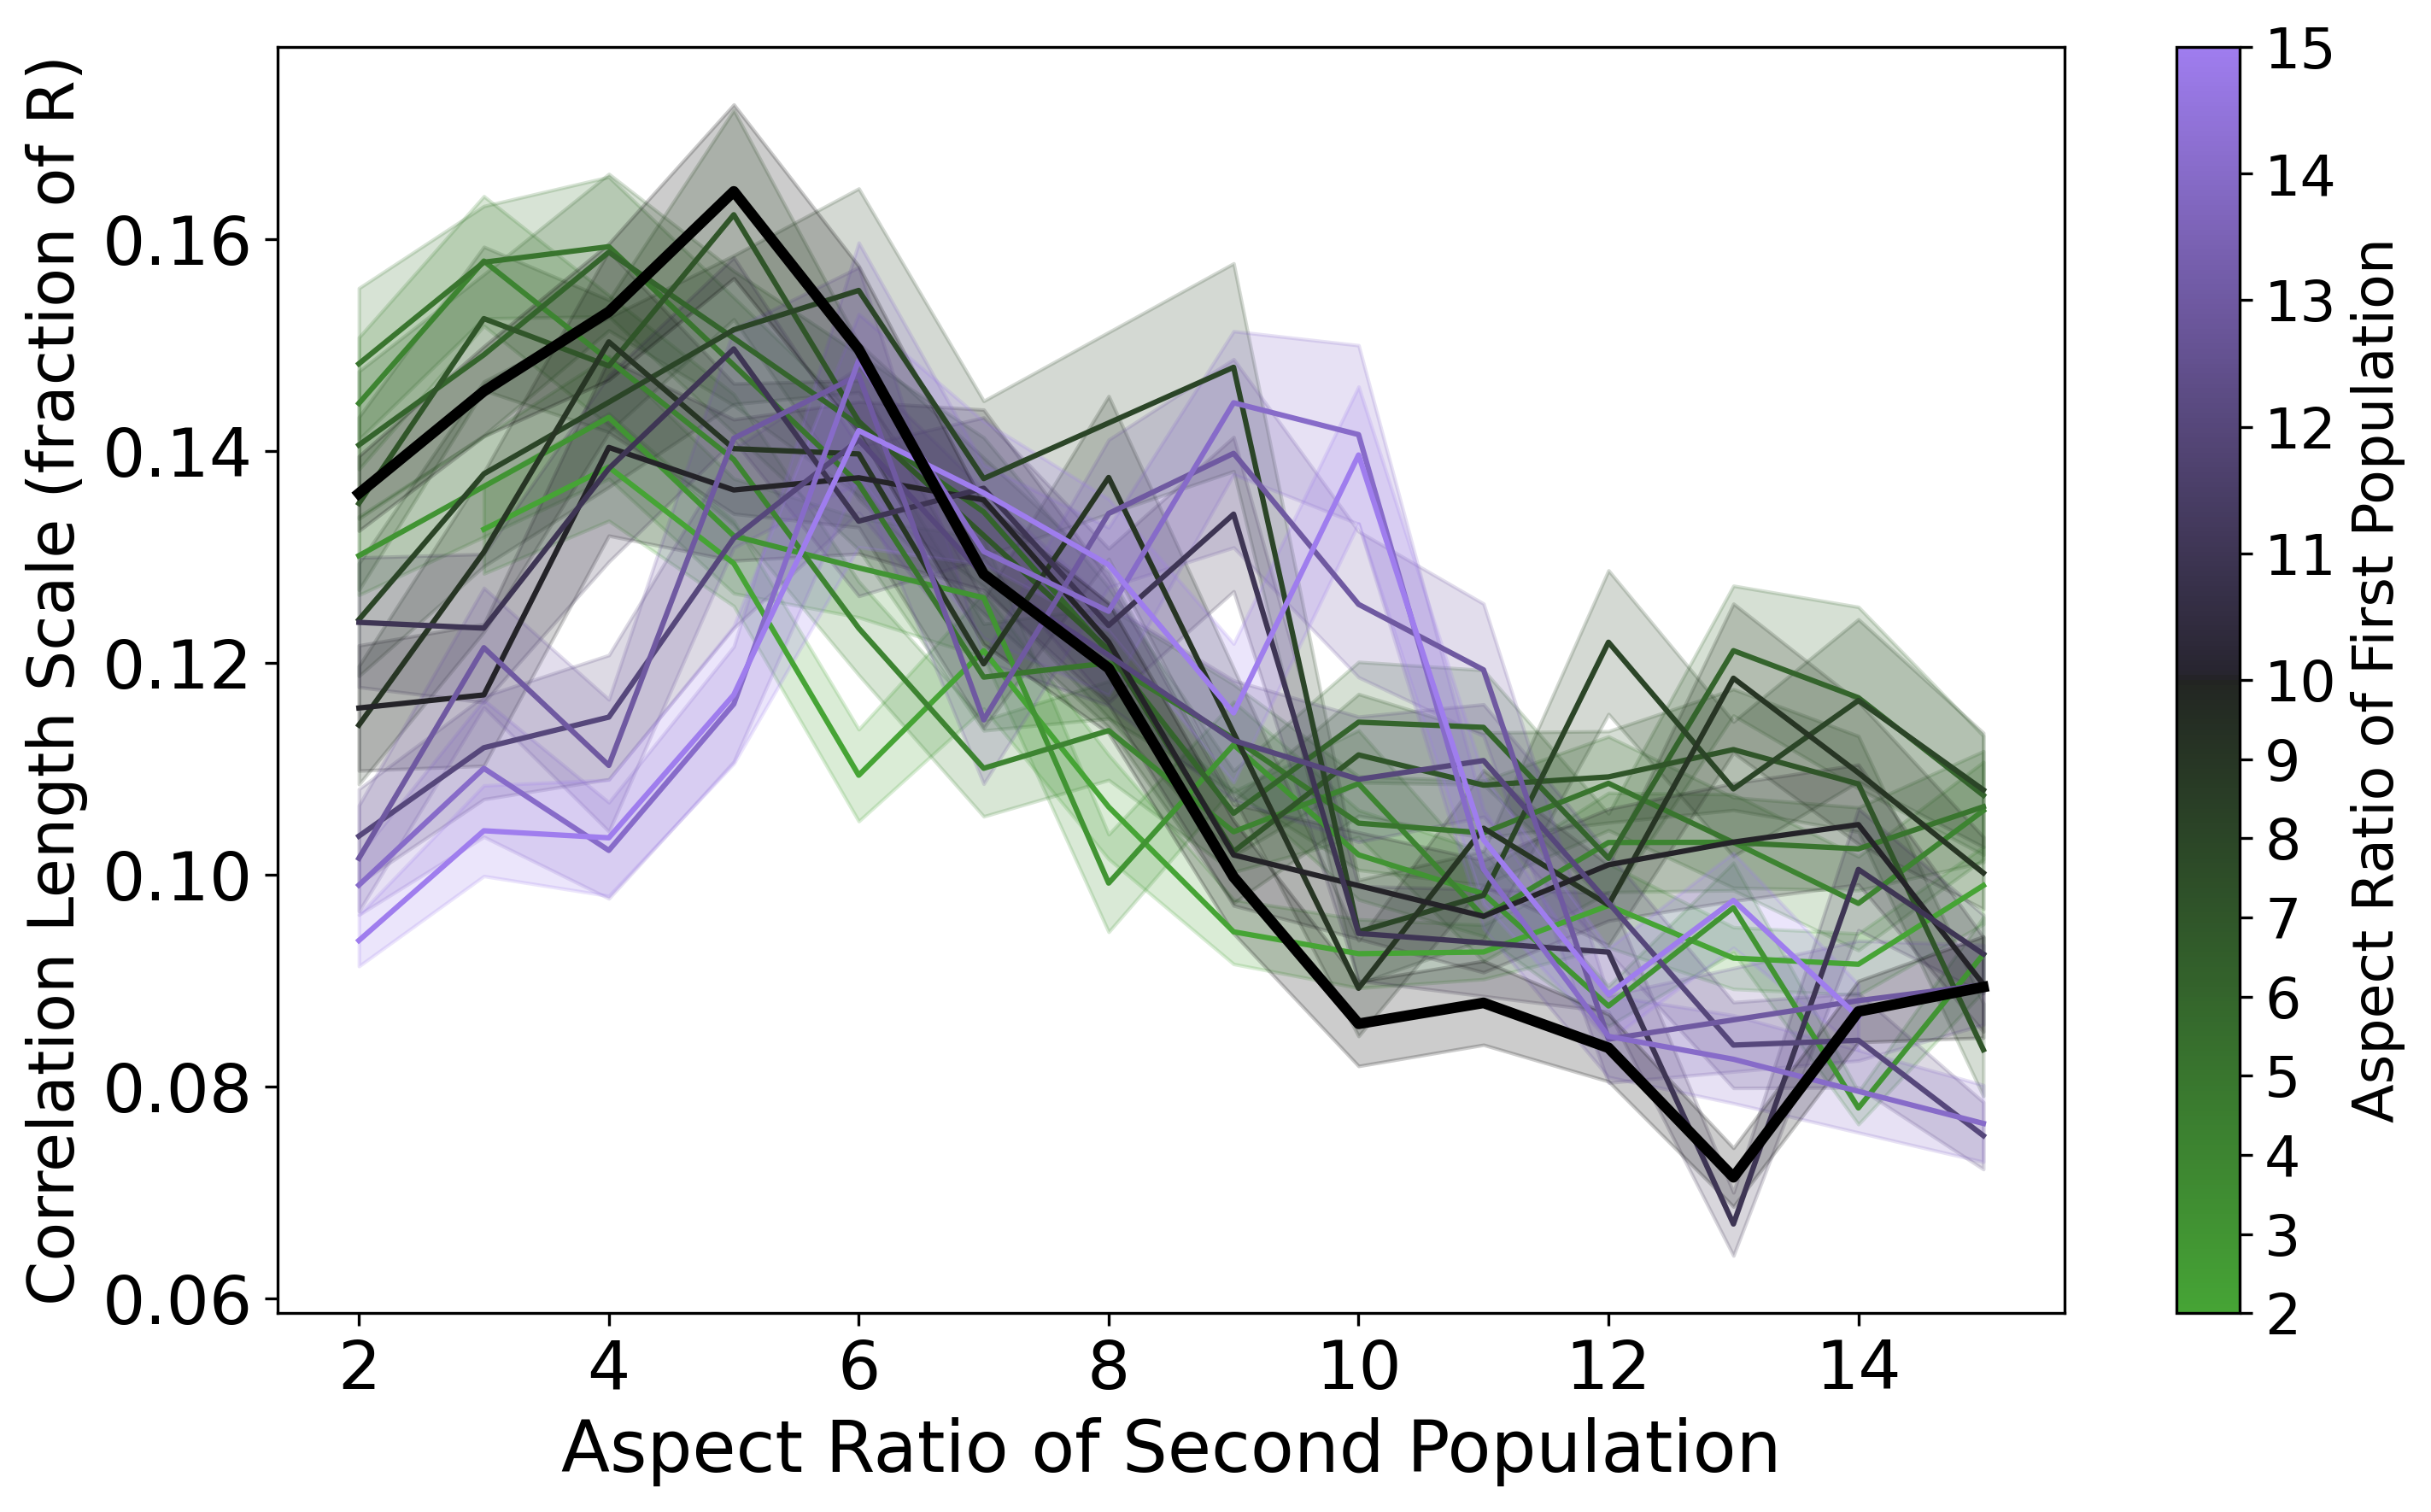

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import curve_fit
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import seaborn as sns


def exponential_decay(x, a, b):
    return a * np.exp(-x / b)


results_df = pd.read_csv("correlation_results.csv")


all_timescales = {}
equal_timescales = {"Asp": [], "Timescale": [], "SEM": []}


for asp1 in range(2, 16):
    subset_df = results_df[results_df["Aspect Ratio 1"] == asp1]
    
    for asp2 in subset_df["Aspect Ratio 2"].unique():
        
        if asp2 == 1:
            continue

        aspect_ratio_subset = subset_df[subset_df["Aspect Ratio 2"] == asp2]

        bins = aspect_ratio_subset["r/R"].values
        avg_correlation = aspect_ratio_subset["Avg Correlation"].values
        sem_correlation = aspect_ratio_subset["SEM Correlation"].values

        
        try:
            popt, pcov = curve_fit(exponential_decay, bins, avg_correlation, maxfev=10000)
            timescale = popt[1]
            timescale_uncertainty = np.sqrt(np.diag(pcov))[1]

            if asp1 == asp2:
                
                equal_timescales["Asp"].append(asp1)
                equal_timescales["Timescale"].append(timescale)
                equal_timescales["SEM"].append(timescale_uncertainty)
            else:
                if asp1 not in all_timescales:
                    all_timescales[asp1] = {"Asp2": [], "Timescale": [], "SEM": []}
                all_timescales[asp1]["Asp2"].append(asp2)
                all_timescales[asp1]["Timescale"].append(timescale)
                all_timescales[asp1]["SEM"].append(timescale_uncertainty)
        except RuntimeError:
            print(f"Failed to fit data for Asp1={asp1}, Asp2={asp2}. Skipping...")
            continue


fig, ax = plt.subplots(figsize=(10, 6), dpi=300)


cmap = sns.diverging_palette(125, 275, s=85, l=60, n=500, center="dark", as_cmap=True)


norm = mcolors.TwoSlopeNorm(vmin=2, vcenter=10, vmax=15)


sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])  
cbar = plt.colorbar(sm, ax=ax, ticks=np.arange(2, 16, 1))
cbar.set_label('Aspect Ratio of First Population', fontsize=16)
cbar.ax.tick_params(labelsize=16)  


for asp1 in range(2, 16):
    if asp1 in all_timescales:
        data = all_timescales[asp1]
        Asp2 = data["Asp2"]
        Timescale = data["Timescale"]
        SEM = data["SEM"]

        
        sorted_indices = np.argsort(Asp2)
        Asp2_sorted = np.array(Asp2)[sorted_indices]
        Timescale_sorted = np.array(Timescale)[sorted_indices]
        SEM_sorted = np.array(SEM)[sorted_indices]

        
        color = cmap(norm(asp1))
        ax.plot(Asp2_sorted, Timescale_sorted, color=color, linewidth=1.5)
        ax.fill_between(Asp2_sorted, Timescale_sorted - SEM_sorted, Timescale_sorted + SEM_sorted, color=color, alpha=0.2)


equal_asp = np.array(equal_timescales["Asp"])
equal_timescales_sorted = np.array(equal_timescales["Timescale"])
equal_sem_sorted = np.array(equal_timescales["SEM"])

ax.plot(equal_asp, equal_timescales_sorted, label='Equal Population Cases (Asp1 = Asp2)', color='black', linewidth=3)  
ax.fill_between(equal_asp, equal_timescales_sorted - equal_sem_sorted, equal_timescales_sorted + equal_sem_sorted, color='black', alpha=0.2)


ax.set_xlabel('Aspect Ratio of Second Population', fontsize=20)
ax.set_ylabel('Correlation Length Scale (fraction of R)', fontsize=18)


ax.tick_params(axis='both', which='major', labelsize=19)  

plt.tight_layout()
plt.savefig('correlation_length_scales_equal_population.png')
plt.show()


/tmp/ipykernel_1213664/1881866975.py:9: RuntimeWarning: overflow encountered in exp
  return a * np.exp(-x / b)


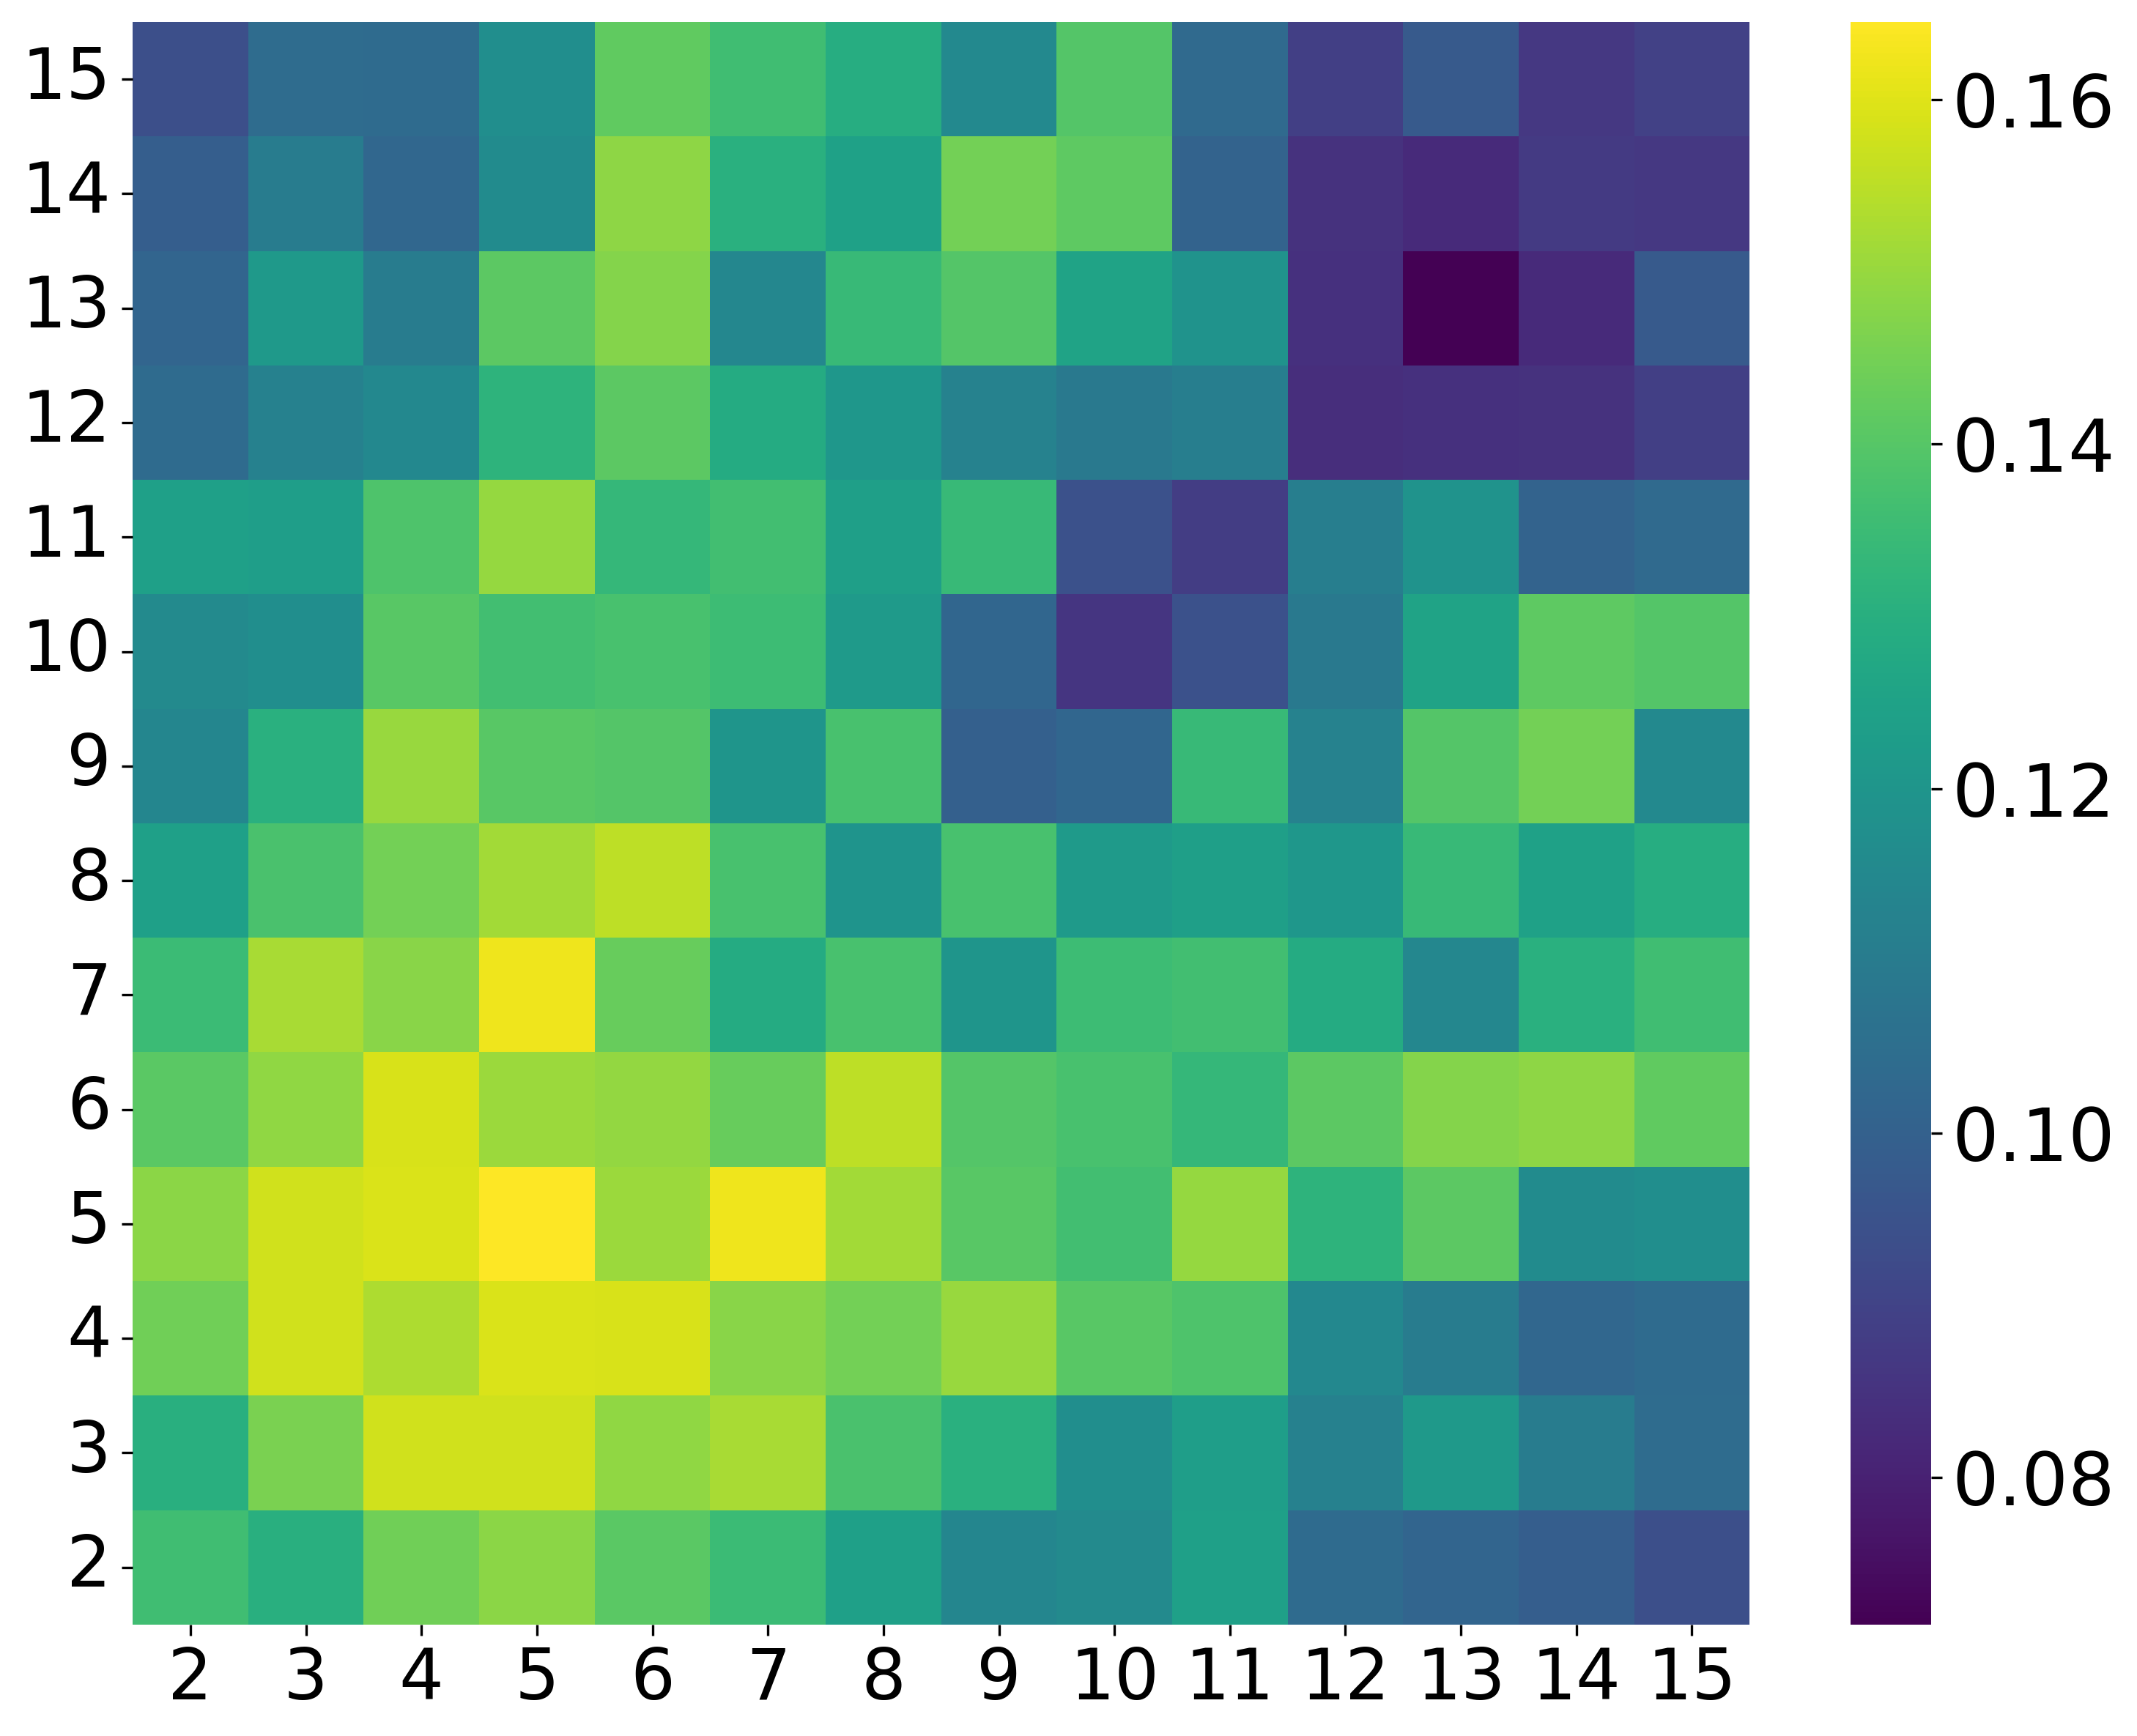

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import curve_fit
import seaborn as sns


def exponential_decay(x, a, b):
    return a * np.exp(-x / b)

#input file
results_df = pd.read_csv("correlation_results.csv")


timescale_matrix = np.full((14, 14), np.nan)  


for asp1 in range(2, 16):
    subset_df = results_df[results_df["Aspect Ratio 1"] == asp1]
    
    for asp2 in subset_df["Aspect Ratio 2"].unique():
        
        if asp2 == 1:
            continue

        aspect_ratio_subset = subset_df[subset_df["Aspect Ratio 2"] == asp2]

        bins = aspect_ratio_subset["r/R"].values
        avg_correlation = aspect_ratio_subset["Avg Correlation"].values

        
        try:
            popt, _ = curve_fit(exponential_decay, bins, avg_correlation, maxfev=10000)
            timescale = popt[1]

            
            timescale_matrix[asp1-2, asp2-2] = timescale
            timescale_matrix[asp2-2, asp1-2] = timescale  
        except RuntimeError:
            print(f"Failed to fit data for Asp1={asp1}, Asp2={asp2}. Skipping...")
            continue


plt.figure(figsize=(10, 8), dpi=300)


ax = sns.heatmap(timescale_matrix, annot=False, cmap='viridis',
                 xticklabels=range(2, 16), yticklabels=range(2, 16), 
                 cbar_kws={})


#plt.xlabel('Aspect Ratio of Population B', fontsize=20)
#plt.ylabel('Aspect Ratio of Population A', fontsize=20)
#plt.title('Correlation Timescale Heatmap', fontsize=22)


ax.invert_yaxis()
plt.yticks(rotation=0)


plt.xticks(fontsize=23)
plt.yticks(fontsize=23)


cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=24)  


plt.tight_layout()
plt.savefig('correlation_timescale_heatmap_symmetric_reversed_y.png')
plt.show()


## Log-lin correlation

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


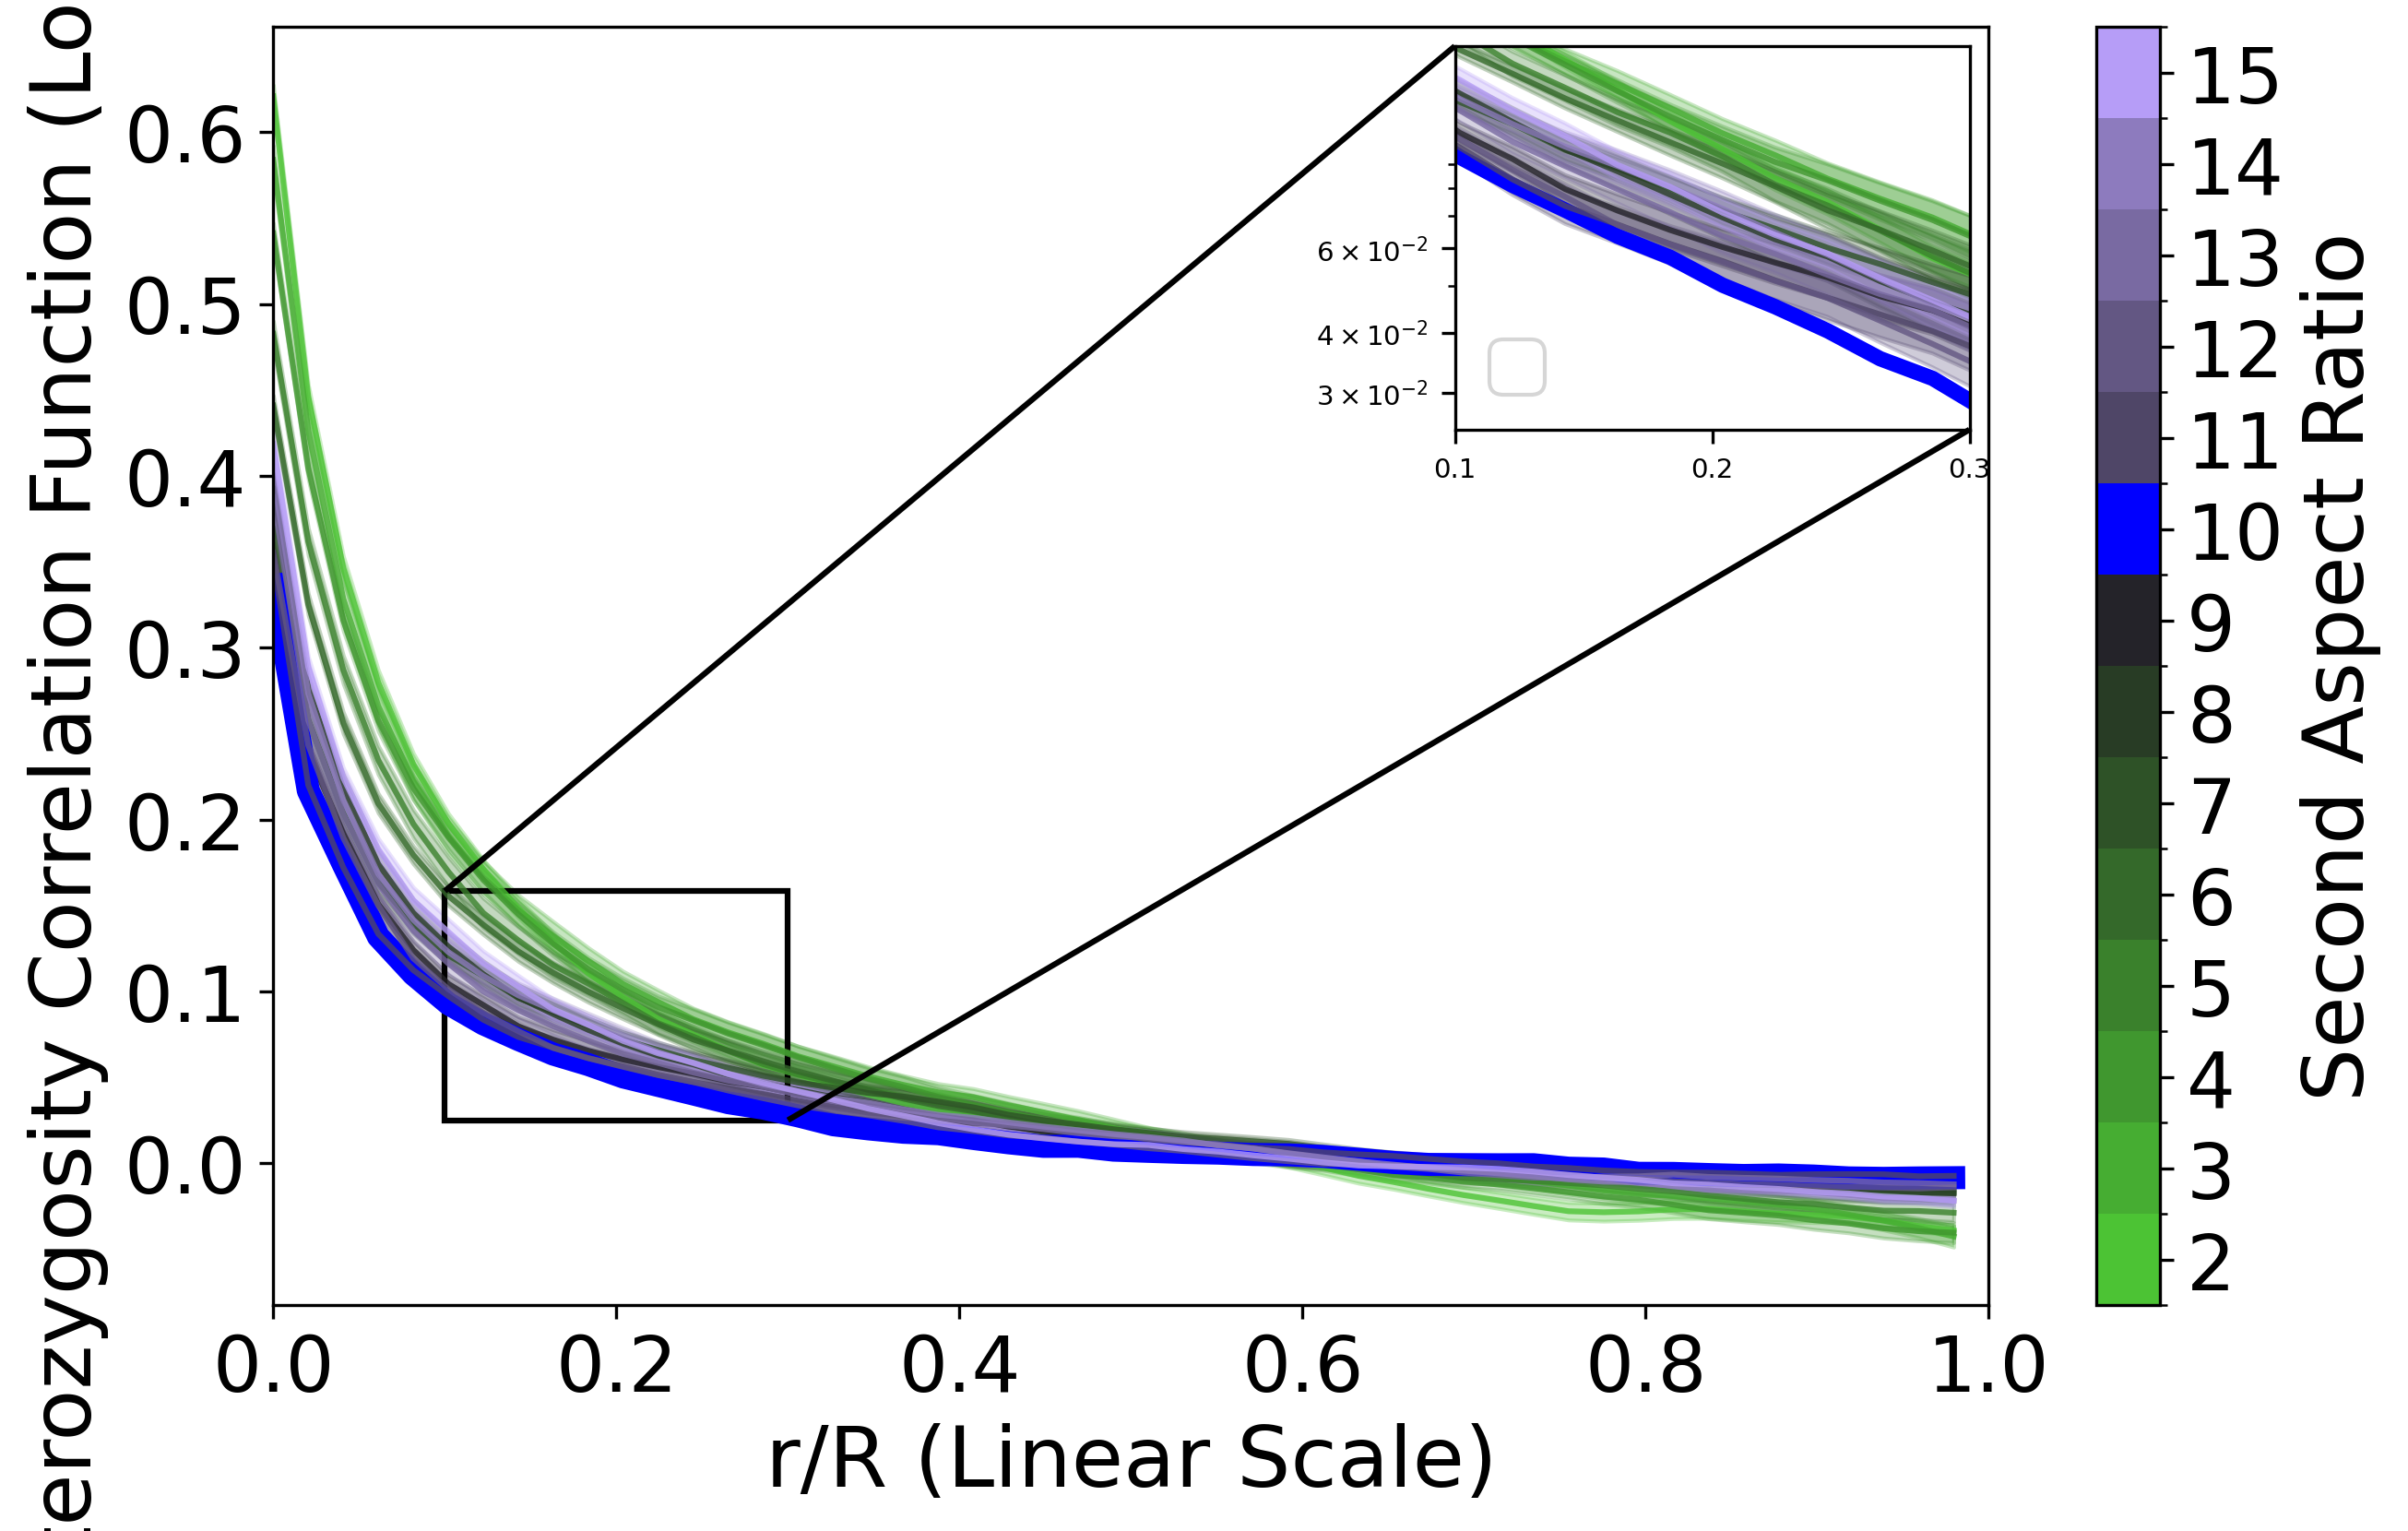

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.cm import ScalarMappable
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
import seaborn as sns


results_df = pd.read_csv("/home/mratman1/activeMatterCommunities/correlation_asp10_paper.csv")


filtered_aspects = {}
for _, row in results_df.iterrows():
    asp1, asp2 = row['asp1'], row['asp2']
    if (asp1, asp2) not in filtered_aspects:
        filtered_aspects[(asp1, asp2)] = {
            'bins': [],
            'avg_correlation': [],
            'sem_correlation': []
        }
    filtered_aspects[(asp1, asp2)]['bins'].append(row['bins'])
    filtered_aspects[(asp1, asp2)]['avg_correlation'].append(row['avg_correlation'])
    filtered_aspects[(asp1, asp2)]['sem_correlation'].append(row['sem_correlation'])

if filtered_aspects:
    
    sorted_aspects = dict(sorted(filtered_aspects.items(), key=lambda x: x[0][1]))

    
    fig, ax = plt.subplots(figsize=(10, 6), dpi=300)

    
    colors = sns.diverging_palette(125, 275, s=90, l=70, n=15, center="dark").as_hex()
    colors[8] = "#0000FF"

    color_map = ListedColormap(colors)
    bounds = np.arange(2, 17, 1)
    norm = BoundaryNorm(bounds, color_map.N)

    sm = ScalarMappable(cmap=color_map, norm=norm)
    sm.set_array([])

    
    for (asp1, asp2), data in sorted_aspects.items():
        bins = np.array(data["bins"])
        avg_correlation = np.array(data["avg_correlation"])
        sem_correlation = np.array(data["sem_correlation"])
        color = color_map(norm(asp2))

        if (asp1, asp2) == (10, 10):
            ax.plot(bins, avg_correlation, color='blue', linewidth=6, label='$a_A = a_B = 10$ (Thicker)')
        else:
            ax.plot(bins, avg_correlation, color=color, alpha=0.8, label=f"$a_B={asp2}$")
            ax.fill_between(bins, avg_correlation - sem_correlation, avg_correlation + sem_correlation, color=color, alpha=0.3)

    
    ax.set_xlabel("r/R (Linear Scale)", fontsize=22)
    ax.set_ylabel("Heterozygosity Correlation Function (Log Scale)", fontsize=22)
    ax.set_xscale('linear')
    ax.set_xlim(0, 1)  
    ax.set_yscale('linear')
    ax.tick_params(axis='both', which='major', labelsize=20)

    
    cbar = fig.colorbar(sm, ax=ax, orientation='vertical', boundaries=bounds, ticks=bounds + 0.5)
    cbar.set_label('Second Aspect Ratio', fontsize=22)
    cbar.ax.set_yticklabels([str(int(i)) for i in bounds])
    cbar.ax.tick_params(labelsize=20)

    
    ax_inset = inset_axes(ax, width="30%", height="30%", loc='upper right')

    for (asp1, asp2), data in sorted_aspects.items():
        bins = np.array(data["bins"])
        avg_correlation = np.array(data["avg_correlation"])
        sem_correlation = np.array(data["sem_correlation"])
        color = color_map(norm(asp2))

        if (asp1, asp2) == (10, 10):
            ax_inset.plot(bins, avg_correlation, color='blue', linewidth=4)  
        else:
            ax_inset.plot(bins, avg_correlation, color=color, alpha=0.8)
            ax_inset.fill_between(bins, avg_correlation - sem_correlation, avg_correlation + sem_correlation, color=color, alpha=0.3)

    
    ax_inset.set_xscale('linear')
    ax_inset.set_yscale('log')
    ax_inset.set_xlim(0.1, 0.3)  
    ax_inset.set_ylim(10**-1.6, 10**-0.8)  

    
    ax_inset.set_yticks([3*10**-2, 4*10**-2, 6*10**-2])  
    ax_inset.set_xticks([0.1, 0.2, 0.3])  
    ax_inset.tick_params(axis='both', which='major', labelsize=10)

    
    mark_inset(ax, ax_inset, loc1=2, loc2=4, fc="none", ec="black", lw=1.5)

    
    plt.legend(fontsize=18, loc='lower left')
    plt.savefig("GRAPH_FOR_CORRELATION_FUNCTION_ASP10_COLORBAR_LIN_LIN_WITH_INSET_CUSTOMIZED.png", bbox_inches='tight', dpi=300)
    plt.show()
else:
    print("No aspect ratios found where the first aspect ratio is 10 and the second aspect ratio is between 2 and 15.")


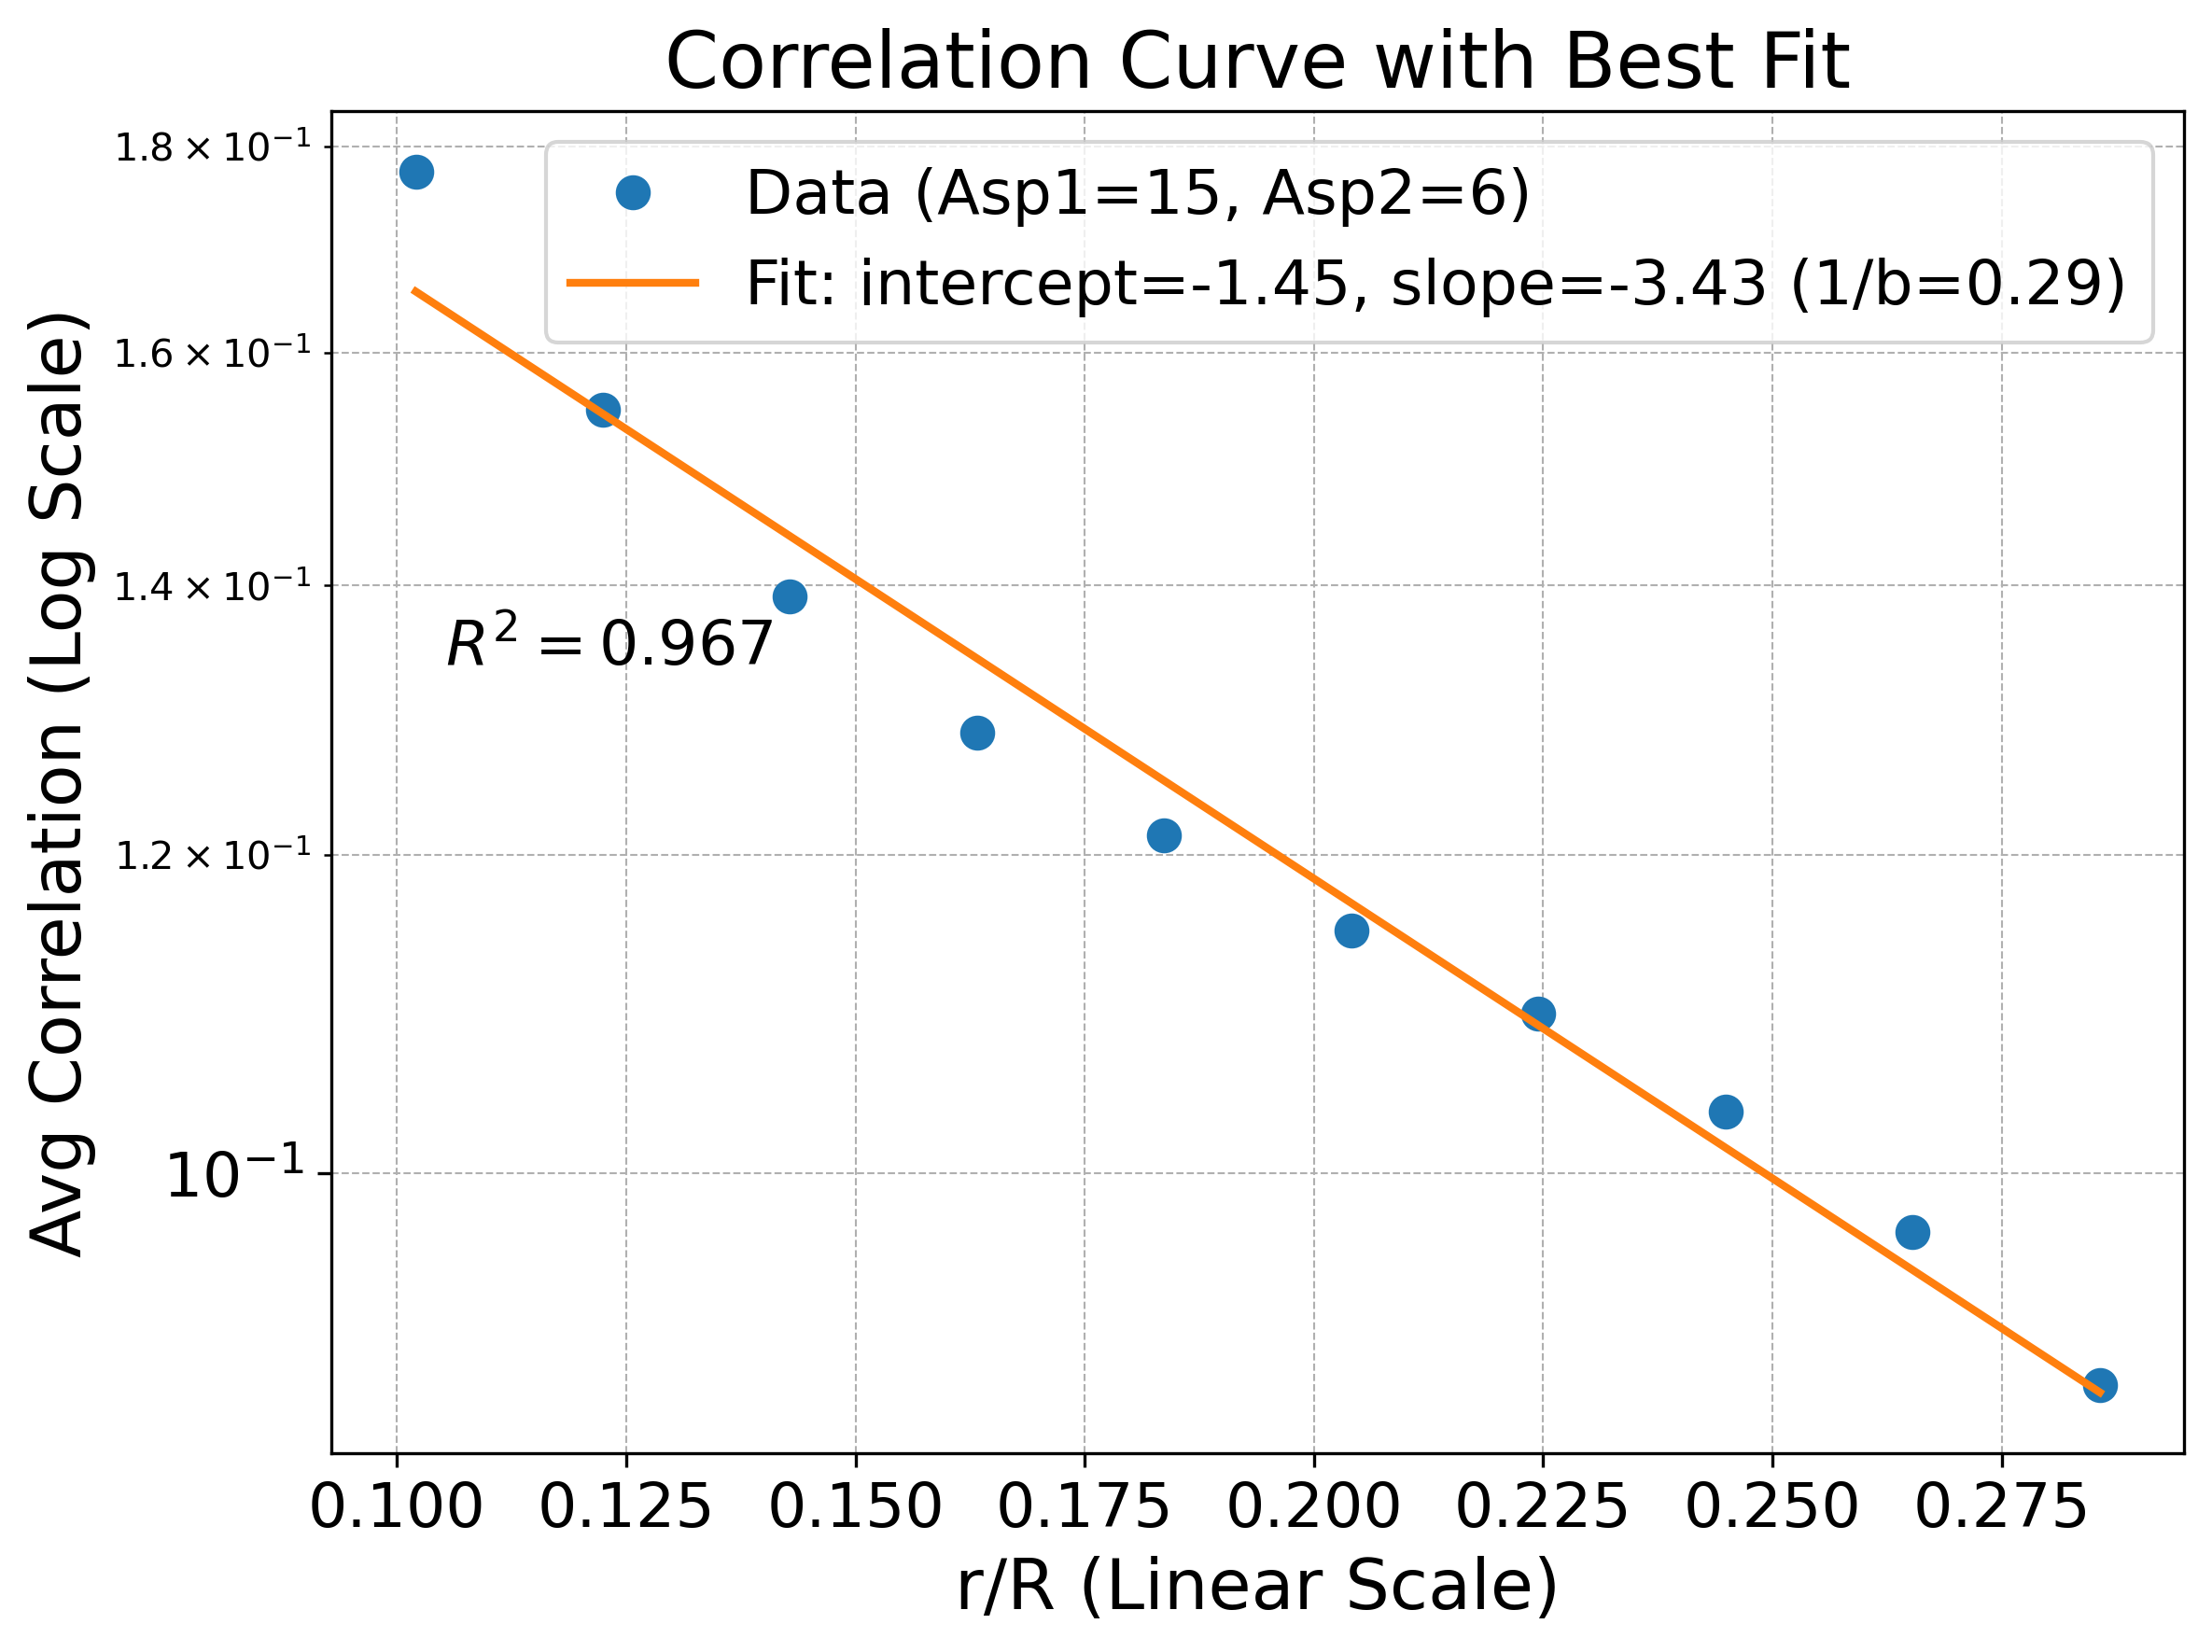

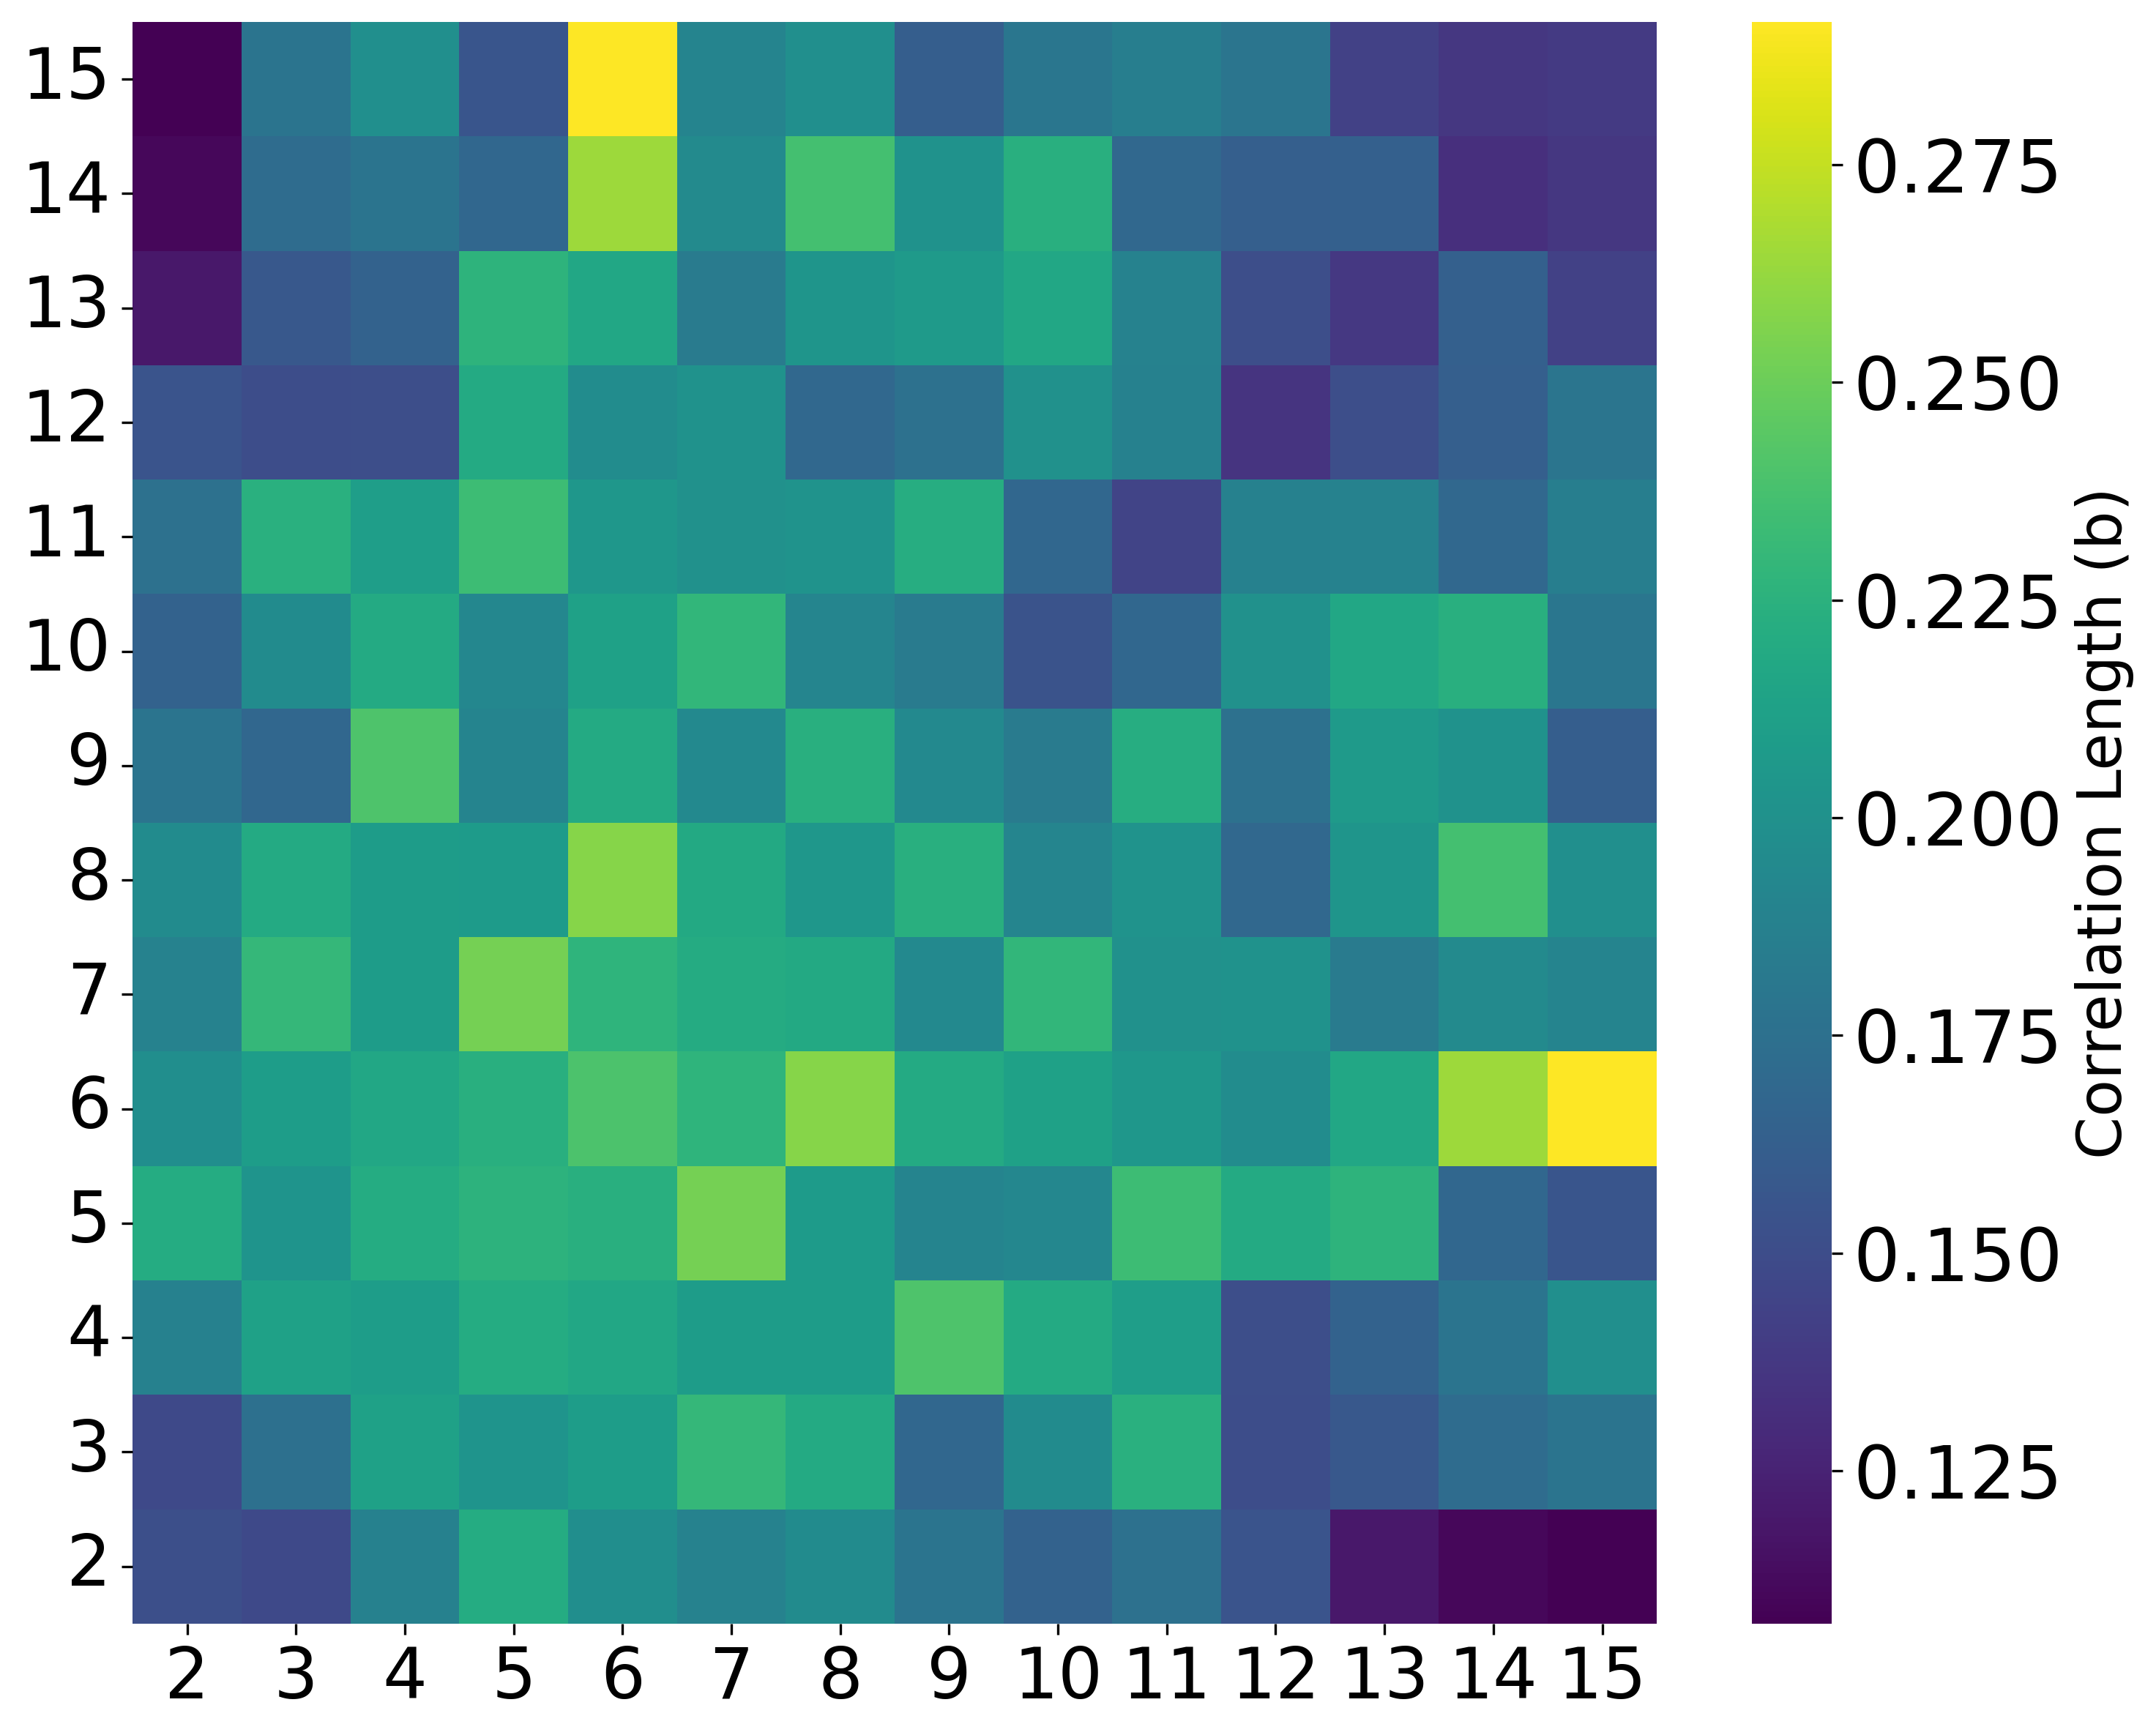

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import curve_fit
import seaborn as sns


def linear_fit(x, intercept, slope):
    return intercept + slope * x


results_df = pd.read_csv("correlation_results.csv")


correlation_length_matrix = np.full((14, 14), np.nan)  


debug_example = None
debug_asp1 = 15
debug_asp2 = 6


for asp1 in range(2, 16):
    subset_df = results_df[results_df["Aspect Ratio 1"] == asp1]
    
    for asp2 in subset_df["Aspect Ratio 2"].unique():
        
        if asp2 == 1:
            continue

        
        aspect_ratio_subset = subset_df[subset_df["Aspect Ratio 2"] == asp2]

        
        bins = aspect_ratio_subset["r/R"].values
        avg_correlation = aspect_ratio_subset["Avg Correlation"].values

        
        mask = (bins >= 0.1) & (bins <= 0.3)
        bins_filtered = bins[mask]
        avg_correlation_filtered = avg_correlation[mask]

        
        try:
            
            log_avg_correlation = np.log(avg_correlation_filtered)

            
            popt, _ = curve_fit(linear_fit, bins_filtered, log_avg_correlation, maxfev=10000)

            
            slope = popt[1]
            correlation_length = -1 / slope

            
            correlation_length_matrix[asp1 - 2, asp2 - 2] = correlation_length
            correlation_length_matrix[asp2 - 2, asp1 - 2] = correlation_length  

            
            if asp1 == debug_asp1 and asp2 == debug_asp2:
                debug_example = {
                    "bins_filtered": bins_filtered,
                    "avg_correlation_filtered": avg_correlation_filtered,
                    "log_avg_correlation": log_avg_correlation,
                    "popt": popt,
                }
        except RuntimeError:
            print(f"Failed to fit data for Asp1={asp1}, Asp2={asp2}. Skipping...")
            continue


if debug_example:
    bins_filtered = debug_example["bins_filtered"]
    avg_correlation_filtered = debug_example["avg_correlation_filtered"]
    log_avg_correlation = debug_example["log_avg_correlation"]
    popt = debug_example["popt"]

    
    avg_correlation_pred = np.exp(linear_fit(bins_filtered, *popt))

    
    residuals = avg_correlation_filtered - avg_correlation_pred
    ss_res = np.sum(residuals**2)
    ss_tot = np.sum((avg_correlation_filtered - np.mean(avg_correlation_filtered))**2)
    r_squared = 1 - (ss_res / ss_tot)

    
    plt.figure(figsize=(8, 6), dpi=300)
    plt.plot(bins_filtered, avg_correlation_filtered, 'o', label=f"Data (Asp1={debug_asp1}, Asp2={debug_asp2})", markersize=8)
    plt.plot(
        bins_filtered,
        avg_correlation_pred,  
        '-', label=f"Fit: intercept={popt[0]:.2f}, slope={popt[1]:.2f} (1/b={-1/popt[1]:.2f})",
        linewidth=2,
    )
    
    
    plt.text(0.15, 0.6, f"$R^2 = {r_squared:.3f}$", fontsize=16, ha='center', va='center', transform=plt.gca().transAxes)

    plt.xlabel("r/R (Linear Scale)", fontsize=18)
    plt.ylabel("Avg Correlation (Log Scale)", fontsize=18)
    plt.yscale('log')
    plt.title("Correlation Curve with Best Fit", fontsize=20)
    plt.legend(fontsize=16)
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.tick_params(axis='both', labelsize=16)  
    plt.tight_layout()
    plt.savefig("debug_correlation_curve_fit.png", dpi=300)
    plt.show()
else:
    print(f"No debug example found for Asp1={debug_asp1}, Asp2={debug_asp2}.")


plt.figure(figsize=(10, 8), dpi=300)


ax = sns.heatmap(correlation_length_matrix, annot=False, cmap='viridis',
                 xticklabels=range(2, 16), yticklabels=range(2, 16),
                 cbar_kws={'label': 'Correlation Length (b)'})


ax.set_xlabel("")
ax.set_ylabel("")
plt.title("")  


ax.invert_yaxis()


plt.xticks(fontsize=23)
plt.yticks(fontsize=23, rotation = 0)


cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=24)
cbar.set_label("Correlation Length (b)", fontsize=20)


plt.tight_layout()
plt.savefig('correlation_length_heatmap_no_titles.png', dpi=300)
plt.show()
